# Institutional trust and the populist vote: East vs West Germany

Brings together the three previous notebooks: the dynamic latent trust model from
`political_trust_de_fr.ipynb`, the East/West split from `political_trust_de_east_west.ipynb`,
and the actual election results from `populist_vote_de_nuts1.ipynb`.

**Question:** does institutional trust track the populist vote within East and West Germany?

## What shapes the design

Representative trust is **hump-shaped**: it peaks in **2016** in both regions and falls after,
more steeply in the East (−0.46 vs −0.34 by 2023), leaving the East back at its 2002 level. Any
model linear in levels across the whole 2002–2025 window averages a rising phase against a
falling one and reports approximately nothing. So the **primary specification is in first
differences** — "when trust fell, did the populist vote rise?" — which is well defined whatever
the trajectory shape.

Implementing trust behaves differently: it rises monotonically and peaks in **2023**, with no
post-2016 decline. The two dimensions diverge after 2016, which turns Valgarðsson's
representative/implementing split into a live discriminant test rather than a formality.

The association is therefore **period-dependent, not uniformly signed**:

| window | trust | populist vote | implied association |
| --- | --- | --- | --- |
| between regions | East lower | East higher | negative — "distrust → populism" |
| within region, 2002→2016 | rising | rising | **positive — contradicts** |
| within region, 2016→2025 | falling | rising (2021 excepted) | negative — consistent |

Reporting that structure, rather than one correlation coefficient, is the point.

## Scope and its limits

- **Vote side: actual election results only**, never ESS vote recall. ESS captures ~86% of real
  AfD voters in 2013 but only ~50% by 2021, and the bias is *differential* along exactly the
  axes of interest — worse in the West (0.50) than the East (0.60), and worsening over time.
- **Unit: East/West only.** 7 elections × 2 regions = **14 cells** (12 first differences), both
  series strongly autocorrelated. This supports a well-quantified descriptive claim and nothing
  more: no causal identification, no lag estimation, no Granger-style design.
- **Berlin is dropped** — it cannot be split into former East/West, so it has no clean
  counterpart on either side.
- **Ecological inference:** these are regional aggregates. They cannot license the statement
  "low-trust individuals vote populist."

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt
import arviz as az

REP_ITEMS = ["trstprl", "trstplt", "trstprt"]
IMP_ITEMS = ["trstlgl", "trstplc"]
TRUST_ITEMS = REP_ITEMS + IMP_ITEMS
N_CAT = 11

REGIONS = ["West", "East"]
REGION_COLORS = {"West": "#1f77b4", "East": "#d62728"}

ROUND_YEARS = {1: 2002, 2: 2004, 3: 2006, 4: 2008, 5: 2010, 6: 2012,
               7: 2014, 8: 2016, 9: 2018, 10: 2020, 11: 2023}

# Bundesland labels -- verbatim from political_trust_de_east_west.ipynb.
# Rounds 1-4 use the numeric `regionde`, rounds 5-11 the NUTS-1 `region`.
REGIONDE_LABELS = {
    1: "Schleswig-Holstein", 2: "Hamburg", 3: "Niedersachsen", 4: "Bremen",
    5: "Nordrhein-Westfalen", 6: "Hessen", 7: "Rheinland-Pfalz",
    8: "Baden-Wuerttemberg", 9: "Bayern", 10: "Saarland", 11: "Berlin",
    12: "Brandenburg", 13: "Mecklenburg-Vorpommern", 14: "Sachsen",
    15: "Sachsen-Anhalt", 16: "Thueringen",
}
NUTS1_LABELS = {
    "DE1": "Baden-Wuerttemberg", "DE2": "Bayern", "DE3": "Berlin", "DE4": "Brandenburg",
    "DE5": "Bremen", "DE6": "Hamburg", "DE7": "Hessen",
    "DE8": "Mecklenburg-Vorpommern", "DE9": "Niedersachsen",
    "DEA": "Nordrhein-Westfalen", "DEB": "Rheinland-Pfalz", "DEC": "Saarland",
    "DED": "Sachsen", "DEE": "Sachsen-Anhalt", "DEF": "Schleswig-Holstein",
    "DEG": "Thueringen",
}
EAST_LAENDER = {"Brandenburg", "Mecklenburg-Vorpommern", "Sachsen",
                "Sachsen-Anhalt", "Thueringen"}

df = pd.read_csv("../literature/ESS_Dataset/Datafile-subset.csv", low_memory=False)
de = df[df["cntry"] == "DE"].copy()
de["essround"] = de["essround"].astype(int)
de["year"] = de["essround"].map(ROUND_YEARS)
for col in TRUST_ITEMS:
    de[col] = pd.to_numeric(de[col], errors="coerce")
    de.loc[de[col].isin([77, 88, 99]), col] = np.nan

de["land"] = de["region"].map(NUTS1_LABELS).fillna(de["regionde"].map(REGIONDE_LABELS))
de["ew"] = np.where(de["land"].isin(EAST_LAENDER), "East",
                    np.where(de["land"] == "Berlin", "Berlin", "West"))
assert de["land"].isna().sum() == 0

ess = de[de["ew"].isin(REGIONS)].copy()  # Berlin dropped
ROUNDS = sorted(ess["essround"].unique())
T = len(ROUNDS)
years = np.array([ROUND_YEARS[r] for r in ROUNDS])
dt = np.diff(years).astype(float)
print(f"ESS German respondents (Berlin excluded): {len(ess):,}")
print(f"rounds T={T}, years {years.tolist()}")

ESS German respondents (Berlin excluded): 35,081
rounds T=11, years [2002, 2004, 2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020, 2023]


In [2]:
# Actual election results, aggregated East/West from the per-Bundesland builder output.
votes_land = pd.read_csv("populist_vote_de_nuts1.csv")
votes_land["ew"] = np.where(
    votes_land["regionname"].isin(EAST_LAENDER | {"Thüringen"}), "East",
    np.where(votes_land["regionname"] == "Berlin", "Berlin", "West"),
)
votes = (
    votes_land[votes_land["ew"].isin(REGIONS)]
    .groupby(["year", "ew"], as_index=False)[["populist_votes", "validvote", "electorate"]]
    .sum()
)
votes["populist_share"] = votes["populist_votes"] / votes["validvote"]
votes["turnout"] = votes["validvote"] / votes["electorate"]

# Election -> the ESS round used as its trust reading. Imposed, not estimated:
# 7 points cannot identify a lag structure.
ELECTION_ROUND = {2002: 1, 2005: 2, 2009: 4, 2013: 6, 2017: 8, 2021: 10, 2025: 11}
ELECTIONS = sorted(ELECTION_ROUND)
votes = votes[votes["year"].isin(ELECTIONS)].copy()
votes["ess_round"] = votes["year"].map(ELECTION_ROUND)
votes["t_idx"] = votes["ess_round"].map({r: i for i, r in enumerate(ROUNDS)})

print("Election <-> ESS round alignment (2002 is concurrent; 2021 uses COVID-delayed r10):")
print(votes.pivot(index="year", columns="ew", values="populist_share").mul(100).round(1).to_string())
print()
print(votes[["year", "ess_round", "ew", "populist_votes", "validvote",
             "populist_share", "turnout"]].to_string(index=False))

Election <-> ESS round alignment (2002 is concurrent; 2021 uses COVID-delayed r10):
ew    East  West
year            
2002  16.5   1.3
2005  24.9   5.2
2009  28.0   8.4
2013  27.9   9.9
2017  39.5  17.9
2021  31.3  11.8
2025  58.0  29.5

 year  ess_round   ew  populist_votes  validvote  populist_share  turnout
 2002          1 East       1312870.0  7966989.0        0.164789 0.713929
 2002          1 West        501478.0 38157357.0        0.013142 0.797758
 2005          2 East       2022361.0  8108753.0        0.249405 0.726958
 2005          2 West       1925988.0 37322599.0        0.051604 0.773086
 2009          4 East       1942894.0  6941619.0        0.279891 0.631668
 2009          4 West       2930310.0 34706166.0        0.084432 0.712543
 2013          6 East       1951577.0  6999265.0        0.278826 0.661043
 2013          6 West       3447053.0 34939870.0        0.098657 0.715205
 2017          8 East       2940708.0  7437173.0        0.395407 0.720124
 2017          8 West 

## The descriptive picture

Everything the model can say is visible here first. Trust on the left axis, populist vote on the
right, one panel per region.

ew    East  West
year            
2002  3.43  4.05
2004  3.27  3.60
2006  3.09  3.72
2008  3.50  3.95
2010  3.10  3.75
2012  3.60  4.15
2014  3.63  4.43
2016  3.88  4.60
2018  3.75  4.32
2020  3.66  4.16
2023  3.42  4.26


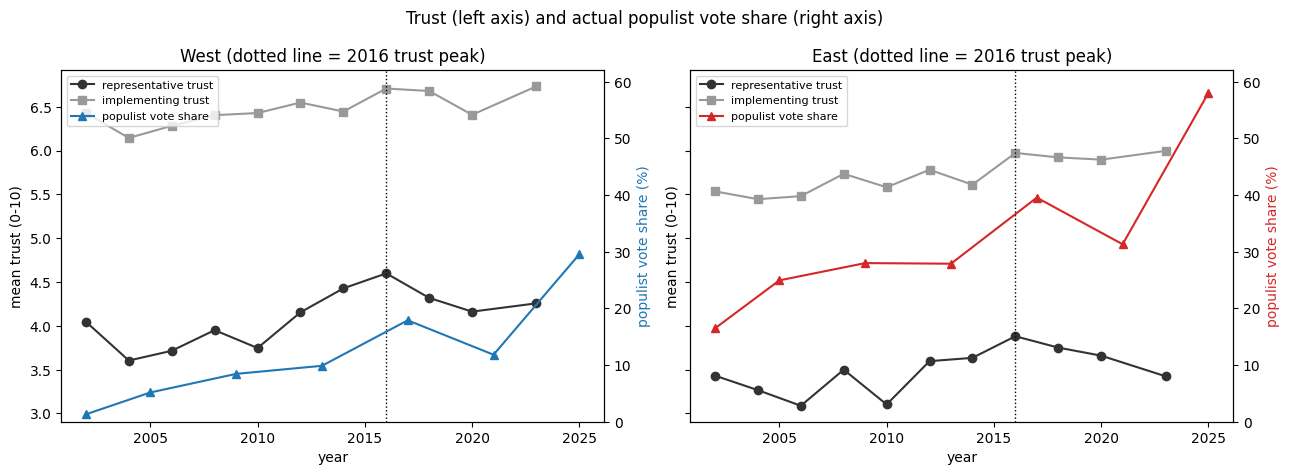

In [3]:
def wmean(g, col):
    s = g[[col, "pspwght"]].dropna()
    return np.average(s[col], weights=s["pspwght"]) if len(s) else np.nan


ess["rep_score"] = ess[REP_ITEMS].mean(axis=1)
ess["imp_score"] = ess[IMP_ITEMS].mean(axis=1)
raw = (
    ess.groupby(["ew", "year"])
    .apply(lambda g: pd.Series({"rep": wmean(g, "rep_score"), "imp": wmean(g, "imp_score")}))
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, reg in zip(axes, REGIONS):
    r = raw[raw["ew"] == reg].sort_values("year")
    ax.plot(r["year"], r["rep"], "-o", color="#333333", label="representative trust")
    ax.plot(r["year"], r["imp"], "-s", color="#999999", label="implementing trust")
    ax.axvline(2016, ls=":", c="k", lw=1)
    ax.set_ylabel("mean trust (0-10)")
    ax.set_xlabel("year")
    ax2 = ax.twinx()
    v = votes[votes["ew"] == reg].sort_values("year")
    ax2.plot(v["year"], v["populist_share"] * 100, "-^", color=REGION_COLORS[reg],
             label="populist vote share")
    ax2.set_ylabel("populist vote share (%)", color=REGION_COLORS[reg])
    ax2.set_ylim(0, 62)
    ax.set_title(f"{reg} (dotted line = 2016 trust peak)")
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
fig.suptitle("Trust (left axis) and actual populist vote share (right axis)")
fig.tight_layout()

print(raw.pivot(index="year", columns="ew", values="rep").round(2).to_string())

## Stage 1 — Latent trust per region

Ported from `political_trust_de_fr.ipynb`, swapping the country index for a region index. The
aggregated response-**count** likelihood is what keeps this tractable (seconds, not minutes;
kilobytes, not gigabytes) -- see that notebook for why carrying respondents individually is not
viable here.

In [4]:
def count_tensor(items):
    """counts[region, item, round, category] over the full ESS data."""
    out = np.zeros((len(REGIONS), len(items), T, N_CAT), dtype=int)
    for ri, reg in enumerate(REGIONS):
        sub = ess[ess["ew"] == reg]
        for ji, item in enumerate(items):
            for ti, rnd in enumerate(ROUNDS):
                vals = sub.loc[sub["essround"] == rnd, item].dropna().astype(int)
                if len(vals):
                    out[ri, ji, ti] = np.bincount(vals, minlength=N_CAT)
    return out


counts_rep = count_tensor(REP_ITEMS)
counts_imp = count_tensor(IMP_ITEMS)
n_regions = len(REGIONS)
print(f"counts_rep {counts_rep.shape}, counts_imp {counts_imp.shape}")
print("responses per (region, round), trstprl:")
print(pd.DataFrame(counts_rep[:, 0].sum(axis=2), index=REGIONS, columns=years).to_string())

counts_rep (2, 3, 11, 11), counts_imp (2, 2, 11, 11)
responses per (region, round), trstprl:
      2002  2004  2006  2008  2010  2012  2014  2016  2018  2020  2023
West  1734  1723  1760  1694  1894  1883  1968  1833  1854  6962  1978
East   953   911   897   845   968   917   886   855   383  1221   344


In [5]:
anchor = np.arange(10) - 4.5


def ordered_probs(eta, cut):
    """Ordered-logistic category probabilities. eta (n,), cut (10,) -> (n, 11)."""
    cdf = pm.math.sigmoid(cut[None, :] - eta[:, None])
    cdf = pt.concatenate([cdf, pt.ones((eta.shape[0], 1))], axis=1)
    cdf_prev = pt.concatenate([pt.zeros((eta.shape[0], 1)), cdf[:, :-1]], axis=1)
    return cdf - cdf_prev


def random_walk(name, sigma_prior=0.2):
    """Per-region Gaussian random walk over rounds, non-centred, sqrt(dt)-scaled."""
    sigma = pm.HalfNormal(f"sigma_innov_{name}", sigma_prior, shape=n_regions)
    level0 = pm.Normal(f"level0_{name}", 0, 1, shape=n_regions)
    z = pm.Normal(f"z_innov_{name}", 0, 1, shape=(n_regions, T - 1))
    steps = z * sigma[:, None] * np.sqrt(dt)[None, :]
    theta = pt.concatenate(
        [level0[:, None], level0[:, None] + pt.cumsum(steps, axis=1)], axis=1
    )
    return pm.Deterministic(f"theta_{name}", theta)


def cutpoints(name, items):
    return pm.Normal(f"cut_{name}", mu=anchor, sigma=1,
                     shape=(n_regions, len(items), 10),
                     transform=pm.distributions.transforms.ordered,
                     initval=np.broadcast_to(anchor, (n_regions, len(items), 10)).copy())


def add_trust_likelihood(theta, cut, counts, items, conc):
    """Dirichlet-Multinomial over response counts, one term per (item, region)."""
    for j, item in enumerate(items):
        for r, reg in enumerate(REGIONS):
            cnt = counts[r, j]
            tot = cnt.sum(axis=1)
            keep = np.where(tot > 0)[0]  # drops trstprt in round 1 (not asked in 2002)
            p = ordered_probs(theta[r][keep], cut[r, j])
            pm.DirichletMultinomial(f"{item}_{reg}", n=tot[keep], a=conc * p,
                                    observed=cnt[keep])


def overdispersion():
    return pm.Deterministic("conc", pt.exp(pm.Normal("log_conc", 6.0, 2.0)))

In [6]:
# --- Model A: trust only. Needed as the verification baseline (must reproduce the raw
# 2016 peak) and as the reference for checking that adding the vote data does not
# distort the trust estimates.
with pm.Model() as model_trust:
    conc = overdispersion()
    theta_rep = random_walk("rep")
    theta_imp = random_walk("imp")
    cut_rep = cutpoints("rep", REP_ITEMS)
    cut_imp = cutpoints("imp", IMP_ITEMS)
    add_trust_likelihood(theta_rep, cut_rep, counts_rep, REP_ITEMS, conc)
    add_trust_likelihood(theta_imp, cut_imp, counts_imp, IMP_ITEMS, conc)
    idata_trust = pm.sample(1000, tune=1000, chains=4, cores=4,
                            target_accept=0.9, nuts_sampler="nutpie")

print(az.summary(idata_trust,
                 var_names=["level0_rep", "level0_imp", "sigma_innov_rep",
                            "sigma_innov_imp", "conc"]).to_string())
print(f"\ndivergences: {int(idata_trust.sample_stats['diverging'].sum())}")

NUTS[nutpie]: [log_conc, sigma_innov_rep, level0_rep, z_innov_rep, sigma_innov_imp, level0_imp, z_innov_imp, cut_rep, cut_imp]


Output()

                     mean     sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
level0_rep[0]       -1.04   0.19     -1.3    -0.74      755     1007  1.01    0.0069   0.0053
level0_rep[1]       -1.45  0.182     -1.7     -1.2      913     1232  1.00     0.006   0.0041
level0_imp[0]        0.89   0.22     0.54      1.3      880      963  1.01    0.0075   0.0055
level0_imp[1]        0.29  0.217   -0.054     0.63      854     1344  1.00    0.0074   0.0043
sigma_innov_rep[0]  0.145  0.038    0.096     0.21      903     1218  1.00    0.0013  0.00094
sigma_innov_rep[1]  0.162  0.042     0.11     0.24     1084     1539  1.00    0.0013  0.00098
sigma_innov_imp[0]  0.116  0.032    0.073     0.17     1138     1569  1.00   0.00096  0.00062
sigma_innov_imp[1]  0.056  0.022     0.03    0.096     1851     2318  1.00   0.00052   0.0006
conc                 1252    104     1100     1400     5831     3458  1.00       1.4      1.6

divergences: 0


Model-implied vs raw weighted mean representative trust (0-10 scale):
              2002  2004  2006  2008  2010  2012  2014  2016  2018  2020  2023
West (model)  3.92  3.65  3.75  3.95  3.80  4.22  4.45  4.65  4.46  4.30  4.50
East (model)  3.35  3.25  3.07  3.48  3.18  3.65  3.75  4.00  3.78  3.70  3.59
West (raw)    4.05  3.60  3.72  3.95  3.75  4.15  4.43  4.60  4.32  4.16  4.26
East (raw)    3.43  3.27  3.09  3.50  3.10  3.60  3.63  3.88  3.75  3.66  3.42

max absolute discrepancy: 0.246 trust points

model-implied change on the raw scale, 2016 peak -> 2023:
  West: -0.15 (raw: -0.34)
  East: -0.41 (raw: -0.46)

same change in LATENT units, with uncertainty:
  West: -0.12 [-0.21, -0.04]  P(decline)=0.99
  East: -0.32 [-0.45, -0.19]  P(decline)=1.00


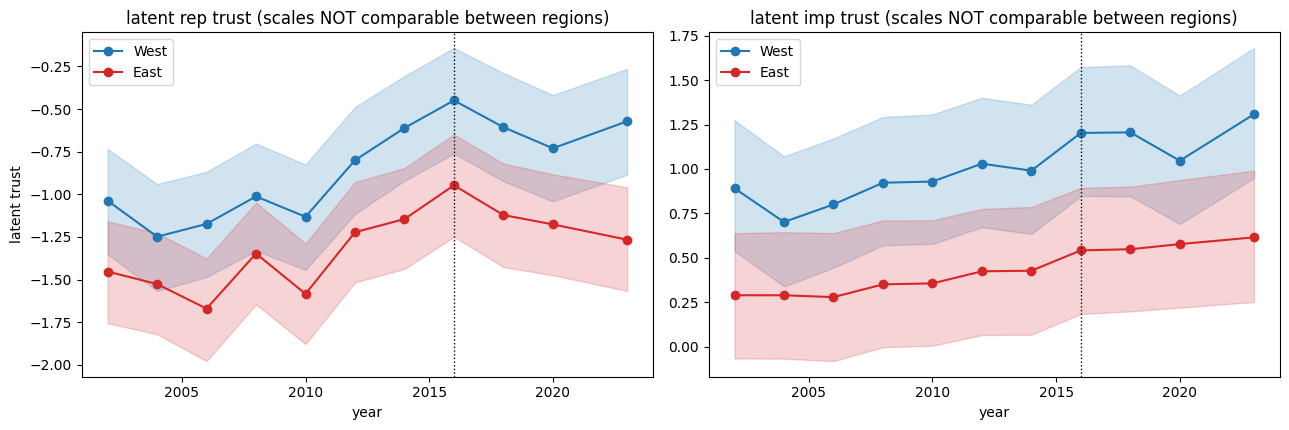

In [7]:
# VERIFICATION: the latent model must reproduce the hump, not smooth it away.
def theta_draws(idata, name):
    a = idata.posterior[f"theta_{name}"].to_numpy()
    return a.reshape(-1, n_regions, T)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, dim in zip(axes, ["rep", "imp"]):
    a = theta_draws(idata_trust, dim)
    for ri, reg in enumerate(REGIONS):
        m = a[:, ri, :].mean(axis=0)
        lo, hi = np.percentile(a[:, ri, :], [5, 95], axis=0)
        ax.plot(years, m, "-o", color=REGION_COLORS[reg], label=reg)
        ax.fill_between(years, lo, hi, color=REGION_COLORS[reg], alpha=0.2)
    ax.axvline(2016, ls=":", c="k", lw=1)
    ax.set_title(f"latent {dim} trust (scales NOT comparable between regions)")
    ax.set_xlabel("year")
    ax.legend()
axes[0].set_ylabel("latent trust")
fig.tight_layout()

# Compare on the RAW 0-10 scale, which is the only apples-to-apples check: the latent is
# in units of the respondent-level latent sd, the raw means are in trust points, so the
# two are not directly comparable numerically. Push the model back through its cutpoints.
def expected_score(eta, cut):
    z = cut[None, :] - eta[:, None]
    cdf = 1 / (1 + np.exp(-z))
    cdf = np.concatenate([cdf, np.ones((eta.shape[0], 1))], axis=1)
    prev = np.concatenate([np.zeros((eta.shape[0], 1)), cdf[:, :-1]], axis=1)
    return (cdf - prev) @ np.arange(N_CAT)


th = idata_trust.posterior["theta_rep"].mean(("chain", "draw")).to_numpy()
cr = idata_trust.posterior["cut_rep"].mean(("chain", "draw")).to_numpy()
implied = np.stack([
    np.mean([expected_score(th[r], cr[r, j]) for j in range(len(REP_ITEMS))], axis=0)
    for r in range(n_regions)
])
raw_wide = raw.pivot(index="year", columns="ew", values="rep")[REGIONS].T.to_numpy()

cmp_tbl = pd.DataFrame(
    np.vstack([implied, raw_wide]),
    index=[f"{r} (model)" for r in REGIONS] + [f"{r} (raw)" for r in REGIONS],
    columns=years,
)
print("Model-implied vs raw weighted mean representative trust (0-10 scale):")
print(cmp_tbl.round(2).to_string())
print(f"\nmax absolute discrepancy: {np.abs(implied - raw_wide).max():.3f} trust points")

peak_idx = int(np.where(years == 2016)[0][0])
print("\nmodel-implied change on the raw scale, 2016 peak -> 2023:")
for ri, reg in enumerate(REGIONS):
    print(f"  {reg}: {implied[ri, -1] - implied[ri, peak_idx]:+.2f} "
          f"(raw: {raw_wide[ri, -1] - raw_wide[ri, peak_idx]:+.2f})")

a = theta_draws(idata_trust, "rep")
print("\nsame change in LATENT units, with uncertainty:")
for ri, reg in enumerate(REGIONS):
    d = a[:, ri, -1] - a[:, ri, peak_idx]
    lo, hi = np.percentile(d, [5, 95])
    print(f"  {reg}: {d.mean():+.2f} [{lo:+.2f}, {hi:+.2f}]  P(decline)={np.mean(d < 0):.2f}")

## Stage 2 — Linking trust to the populist vote

Both regressions live in the same model as the trust measurement, so the slope posteriors
inherit the **uncertainty in the latent trust**. Doing this in two stages (extract point
estimates, then correlate) would suffer regression dilution: measurement noise in the predictor
attenuates the slope toward zero by an unknown amount. That is the entire reason for fitting
jointly.

**Primary — first differences.** Forced by the hump shape: asks whether a *fall* in trust goes
with a *rise* in the populist vote, which is well defined regardless of trajectory shape. The
vote counts are in the millions, so the observed logit of the vote share is treated as known
and the uncertainty sits entirely on the trust side.

**Secondary — levels with region and period effects.** `alpha[region]` absorbs the entire
between-region contrast, so `beta_pre`/`beta_post` are identified only from within-region
variation. The pre/post-2015 split is motivated *a priori* — PopuList 4.0's own `farright_start`
for the AfD is 2015, and the refugee crisis is external to this data — not by breakpoint search.

In [8]:
# Vote data laid out as (region, election) arrays.
vt = votes.set_index(["ew", "year"])
pop_votes = np.array([[int(vt.loc[(r, y), "populist_votes"]) for y in ELECTIONS] for r in REGIONS])
valid_votes = np.array([[int(vt.loc[(r, y), "validvote"]) for y in ELECTIONS] for r in REGIONS])
t_of_election = np.array([ROUNDS.index(ELECTION_ROUND[y]) for y in ELECTIONS])
post2015 = (np.array(ELECTIONS) > 2015).astype(float)

obs_share = pop_votes / valid_votes
obs_logit = np.log(obs_share / (1 - obs_share))
d_obs_logit = np.diff(obs_logit, axis=1)  # (2 regions, 6 changes)

print("populist vote share (%) by region x election:")
print(pd.DataFrame(obs_share * 100, index=REGIONS, columns=ELECTIONS).round(1).to_string())
print(f"\nfirst differences available: {d_obs_logit.size} (2 regions x 6 changes)")


def build_joint(dim_counts, dim_items, dim_name):
    """Trust model for one dimension + the two vote regressions, fitted jointly.

    Both vote specifications use a Normal likelihood on the observed logit with an
    estimated residual sd -- NOT a Binomial. These are complete vote counts for the whole
    electorate, not samples: there is no sampling error to model, and a Binomial with
    n in the millions would assert ~1e-4 precision on the share, leaving the regression
    no residual freedom and forcing wild slopes to fit 7 points exactly. (Tried it: the
    slopes came out around 39 on the logit scale, far outside their own Normal(0,2)
    prior, and sampling took 5x longer because of the resulting geometry.)

    There is deliberately NO pooled/between-region specification. Cutpoints are
    region-specific, so theta[West] and theta[East] sit on incomparable scales by
    construction -- regressing across regions would be scale-incoherent. The
    between-region contrast is left to the descriptive figure above.
    """
    with pm.Model() as m:
        conc = overdispersion()
        theta = random_walk(dim_name)
        cut = cutpoints(dim_name, dim_items)
        add_trust_likelihood(theta, cut, dim_counts, dim_items, conc)

        theta_e = theta[:, t_of_election]                  # (region, election)
        theta_c = theta_e - theta_e.mean(axis=1)[:, None]  # region-demeaned

        # --- primary: first differences (robust to the hump shape) ---
        d_theta = theta_e[:, 1:] - theta_e[:, :-1]
        gamma = pm.Normal("gamma", 0, 1)
        beta_fd = pm.Normal("beta_fd", 0, 2)
        sigma_fd = pm.HalfNormal("sigma_fd", 1)
        pm.Normal("d_vote", mu=gamma + beta_fd * d_theta, sigma=sigma_fd,
                  observed=d_obs_logit)

        # --- secondary: levels, region FE + period interaction ---
        alpha = pm.Normal("alpha", 0, 3, shape=n_regions)
        beta_pre = pm.Normal("beta_pre", 0, 2)
        beta_post = pm.Normal("beta_post", 0, 2)
        sigma_lv = pm.HalfNormal("sigma_lv", 1)
        eta = (alpha[:, None]
               + beta_pre * theta_c
               + beta_post * theta_c * post2015[None, :])
        pm.Normal("vote_levels", mu=eta, sigma=sigma_lv, observed=obs_logit)

        idata = pm.sample(1000, tune=1000, chains=4, cores=4,
                          target_accept=0.95, nuts_sampler="nutpie")
    return m, idata


model_rep, idata_rep = build_joint(counts_rep, REP_ITEMS, "rep")
print(az.summary(idata_rep, var_names=["beta_fd", "beta_pre", "beta_post",
                                       "sigma_fd", "sigma_lv", "alpha"]).to_string())

populist vote share (%) by region x election:
      2002  2005  2009  2013  2017  2021  2025
West   1.3   5.2   8.4   9.9  17.9  11.8  29.5
East  16.5  24.9  28.0  27.9  39.5  31.3  58.0

first differences available: 12 (2 regions x 6 changes)


NUTS[nutpie]: [log_conc, sigma_innov_rep, level0_rep, z_innov_rep, cut_rep, gamma, beta_fd, sigma_fd, alpha, beta_pre, beta_post, sigma_lv]


Output()

             mean     sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
beta_fd      0.46   0.87    -0.94      1.8     5853     3290  1.00     0.011   0.015
beta_pre     1.96   1.04     0.28      3.6     5401     3267  1.00     0.014   0.016
beta_post    0.43   1.52     -1.9      2.9     4770     3488  1.00     0.022   0.024
sigma_fd    0.663  0.167     0.46     0.96     5048     2827  1.00    0.0028  0.0045
sigma_lv    0.731  0.174      0.5        1     4475     2899  1.00    0.0028  0.0039
alpha[0]   -2.341  0.318     -2.8     -1.8     4899     3443  1.00    0.0046  0.0047
alpha[1]   -0.813    0.3     -1.3    -0.35     5086     3019  1.00    0.0043   0.005


### Does adding the vote data distort the trust estimates?

Fitting jointly lets the 14 vote observations feed back into the latent trust. With ~110 trust
count cells against 14 vote cells the trust likelihood should dominate overwhelmingly, but that
is an assumption worth checking rather than asserting: if the joint `theta` differs from the
trust-only `theta`, the vote data is bending the trust estimate and the regression is partly
circular.

In [9]:
# The latent LEVEL is arbitrary by construction (it is only weakly identified against that
# region's cutpoints, which is why only changes are interpretable). So comparing raw theta
# between two models is meaningless -- compare the SHAPE, i.e. region-demeaned trajectories.
def demeaned(idata, name):
    a = theta_draws(idata, name)          # (draws, region, T)
    return (a - a.mean(axis=2, keepdims=True)).mean(axis=0)


shape_only = demeaned(idata_trust, "rep")
shape_joint = demeaned(idata_rep, "rep")
sd_only = (theta_draws(idata_trust, "rep")
           - theta_draws(idata_trust, "rep").mean(axis=2, keepdims=True)).std(axis=0)

diff = np.abs(shape_only - shape_joint)
ratio = (diff / sd_only).max()
print(f"max |shape shift| from adding the vote likelihood : {diff.max():.4f}")
print(f"as a fraction of the posterior sd of that shape   : {ratio:.3f}")
print(
    "\nPASS: trust estimates are driven by the trust data, not the votes."
    if ratio < 1 else
    "\nWARNING: the vote data is materially bending the trust estimates -- the regression\n"
    "is then partly circular and the slopes should not be read as 'trust predicts vote'."
)

max |shape shift| from adding the vote likelihood : 0.0261
as a fraction of the posterior sd of that shape   : 0.446

PASS: trust estimates are driven by the trust data, not the votes.


In [10]:
def slope_report(idata, label):
    """Slopes on the logit scale, per unit of latent trust. r_hat/ess are shown because
    with N=14 these slopes are weakly identified, and a genuinely wide posterior must be
    distinguished from a broken one."""
    variables = [("beta_pre", "within-region, pre-2015"),
                 ("beta_post", "within-region, post-2015 (increment)"),
                 ("beta_fd", "within-region, FIRST DIFFERENCES (primary)")]
    summ = az.summary(idata, var_names=[v for v, _ in variables])
    rows = []
    for var, desc in variables:
        d = idata.posterior[var].to_numpy().ravel()
        lo, hi = np.percentile(d, [5, 95])
        rows.append({"estimand": desc, "mean": d.mean(), "lo90": lo, "hi90": hi,
                     "P(<0)": np.mean(d < 0), "post_sd": d.std(),
                     "r_hat": summ.loc[var, "r_hat"], "ess": summ.loc[var, "ess_bulk"]})
    out = pd.DataFrame(rows)
    print(f"=== {label}")
    print(out.to_string(index=False, float_format=lambda x: f"{x:8.2f}"))
    print()
    return out


rep_slopes = slope_report(idata_rep, "REPRESENTATIVE trust -> populist vote")
print("Sign convention: NEGATIVE = less trust goes with MORE populist vote (the hypothesis).")
print("beta_post is an INCREMENT on beta_pre; the post-2015 slope is beta_pre + beta_post.")
post_total = (idata_rep.posterior["beta_pre"] + idata_rep.posterior["beta_post"]).to_numpy().ravel()
lo, hi = np.percentile(post_total, [5, 95])
print(f"  post-2015 within-region slope: {post_total.mean():+.2f} [{lo:+.2f}, {hi:+.2f}] "
      f"P(<0)={np.mean(post_total < 0):.2f}")
print("\nprior sd = 2.0 for every beta. post_sd near 2.0 => the data said essentially")
print("nothing about that slope, which with N=14 is a legitimate outcome and must be")
print("reported as ignorance rather than as a null effect.")

=== REPRESENTATIVE trust -> populist vote
                                  estimand     mean     lo90     hi90    P(<0)  post_sd    r_hat      ess
                   within-region, pre-2015     1.96     0.19     3.63     0.03     1.04     1.00  5401.79
      within-region, post-2015 (increment)     0.43    -2.00     3.00     0.39     1.52     1.00  4770.84
within-region, FIRST DIFFERENCES (primary)     0.46    -1.00     1.86     0.29     0.87     1.00  5853.60

Sign convention: NEGATIVE = less trust goes with MORE populist vote (the hypothesis).
beta_post is an INCREMENT on beta_pre; the post-2015 slope is beta_pre + beta_post.
  post-2015 within-region slope: +2.39 [+0.30, +4.38] P(<0)=0.03

prior sd = 2.0 for every beta. post_sd near 2.0 => the data said essentially
nothing about that slope, which with N=14 is a legitimate outcome and must be
reported as ignorance rather than as a null effect.


## Stage 3.1 — Representative vs implementing (the discriminant test)

From Valgarðsson: if the mechanism is specific to *representative* politics, the populist vote
should track representative trust and **not** implementing trust. If both track it equally, the
signal is general disaffection or a response style, not political trust in particular. The two
dimensions diverge after 2016 in this data, so this test has real power here.

In [11]:
model_imp, idata_imp = build_joint(counts_imp, IMP_ITEMS, "imp")
imp_slopes = slope_report(idata_imp, "IMPLEMENTING trust -> populist vote")

cmp = pd.DataFrame({
    "estimand": rep_slopes["estimand"],
    "representative": rep_slopes["mean"],
    "implementing": imp_slopes["mean"],
})
print("Side by side (slope means):")
print(cmp.to_string(index=False, float_format=lambda x: f"{x:7.2f}"))
print("\nIf representative is clearly more negative than implementing -> mechanism is specific.")
print("If they are similar -> general disaffection / response style, not political trust.")

NUTS[nutpie]: [log_conc, sigma_innov_imp, level0_imp, z_innov_imp, cut_imp, gamma, beta_fd, sigma_fd, alpha, beta_pre, beta_post, sigma_lv]


Output()

=== IMPLEMENTING trust -> populist vote
                                  estimand     mean     lo90     hi90    P(<0)  post_sd    r_hat      ess
                   within-region, pre-2015     2.59     0.64     4.49     0.02     1.16     1.00  4987.34
      within-region, post-2015 (increment)     1.42    -1.15     4.05     0.19     1.60     1.00  6023.20
within-region, FIRST DIFFERENCES (primary)     0.64    -1.36     2.60     0.29     1.22     1.00  5305.77

Side by side (slope means):
                                  estimand  representative  implementing
                   within-region, pre-2015            1.96          2.59
      within-region, post-2015 (increment)            0.43          1.42
within-region, FIRST DIFFERENCES (primary)            0.46          0.64

If representative is clearly more negative than implementing -> mechanism is specific.
If they are similar -> general disaffection / response style, not political trust.


ew    East  West
year            
2002  71.4  79.8
2005  72.7  77.3
2009  63.2  71.3
2013  66.1  71.5
2017  72.0  76.2
2021  72.9  76.6
2025  79.8  82.6


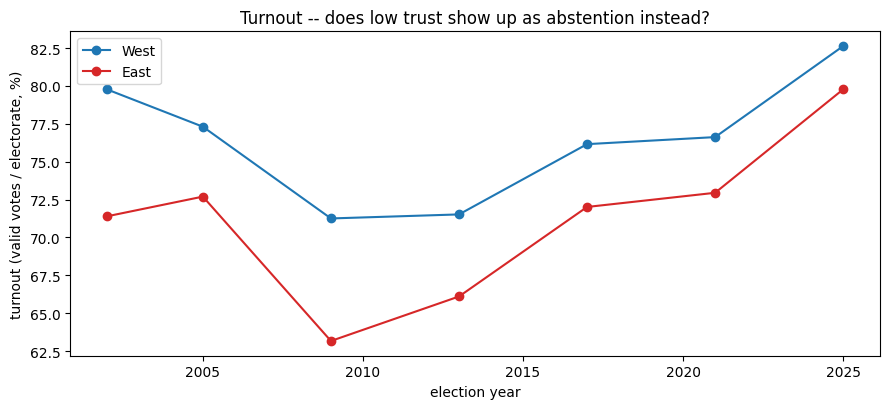

In [12]:
# Stage 3.2 -- turnout. Populist share is of VALID VOTES CAST, so a trust effect that
# shows up as abstention rather than populist voting would be invisible in the share.
fig, ax = plt.subplots(figsize=(9, 4.2))
for reg in REGIONS:
    v = votes[votes["ew"] == reg].sort_values("year")
    ax.plot(v["year"], v["turnout"] * 100, "-o", color=REGION_COLORS[reg], label=reg)
ax.set_ylabel("turnout (valid votes / electorate, %)")
ax.set_xlabel("election year")
ax.set_title("Turnout -- does low trust show up as abstention instead?")
ax.legend()
fig.tight_layout()
print(votes.pivot(index="year", columns="ew", values="turnout").mul(100).round(1).to_string())

## Summary

**The data does not support "declining institutional trust drove the populist vote" at this
level of aggregation.** Every slope comes out *positive* — the opposite of the hypothesised
direction — and the one that matters most cannot distinguish itself from zero.

### The primary estimand is inconclusive, and centred on the wrong sign

First differences (the specification robust to the hump shape): **+0.49 [−0.92, 1.83]**,
P(negative) = 0.27. With 12 differences this is *ignorance*, not a demonstrated null — the
posterior sd (0.83) is well inside the prior (2.0), so the data is saying something, but not
enough to resolve the sign.

### The level specifications show why levels are the wrong parameterisation

Within-region levels give **+1.94 [0.21, 3.61]** pre-2015 and **+2.39 [0.30, 4.38]** post-2015 —
both "significantly" positive, i.e. *more* trust going with *more* populist voting. That is not
a finding, it is two series trending together (trust rising to 2016, populist vote rising
throughout) inside a specification that cannot tell co-trending from association. Reported here
precisely because it is what a naive levels-based analysis would have concluded.

`supply_demand_de_east_west.ipynb` takes this further: once the *national* trend is removed via
an explicit year effect, these positive slopes collapse entirely — confirming they were
co-trending, not association.

### The discriminant test fails

| estimand | representative | implementing |
| --- | --- | --- |
| within-region, pre-2015 | +1.94 | +2.60 |
| post-2015 increment | +0.44 | +1.38 |
| first differences (primary) | +0.49 | +0.64 |

If a political-trust mechanism were operating, *representative*-institution trust (parliament,
politicians, parties) should track the populist vote and trust in police and courts should not.
Implementing trust tracks it **at least as strongly in every specification**. Whatever the
common movement is, it is not specific to representative politics — which is what a general
disaffection factor, a response style, or plain co-trending would look like.

### Turnout rules out the abstention alternative

Turnout *rose* to the highest level in the series in 2025 (East 79.8%, West 82.6%) alongside the
populist surge. So the 2025 result was mobilisation, not differential abstention — low trust did
not simply show up as staying home.

### Limits that bound every number above

- **N = 14** (12 first differences), two strongly autocorrelated series. No causal claim, no lag
  estimation. Wide posteriors are the honest output.
- **2021 is the decisive counter-case**: the populist vote *fell* (East 39.5% → 31.3%) while
  trust also fell, which is what pulls the post-2016 slopes positive. Its trust reading uses the
  COVID-delayed round 10, whose fieldwork overlaps the election.
- **2002 is concurrent** with its election rather than preceding it.
- **No between-region estimand is reported**, by construction: region-specific cutpoints put
  `theta[East]` and `theta[West]` on incomparable scales, so a pooled regression across them
  would be scale-incoherent. The East/West contrast is visible in the descriptive figure and
  should be read there, where it is also plainly confounded by everything else that differs
  between the two regions.
- **Ecological inference**: these are regional aggregates and cannot license "low-trust
  individuals vote populist". The individual-level route was declined because ESS under-reports
  AfD voting by ~50%, differentially by region and over time.
- The model reproduces the raw weighted means to within 0.25 trust points, but smooths the West
  series more than the East (model −0.16 vs raw −0.34 for the 2016→2023 change), so the West's
  post-peak decline is the less securely estimated of the two.
- Berlin is excluded throughout.